# Framework Validation

## NTS0611 unconstrained distribution consistency

This validation evaluates every unique unconstrained `Age × Sex` lookup combination available in the final demographic profile space. For each combination, the expected trip-purpose distribution is extracted independently from the harmonised NTS0611 dataset and compared with the framework output. The NTS0611 dataset values are not produced with the framework lookup or constraint functions.

### 1. Setup and data loading

In [1]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Load the inputs required to validate all unique unconstrained
# NTS0611 Age-Sex lookup combinations.

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

TOLERANCE = 1e-8

project_root = Path.cwd().parents[1]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

profile_space_path = (
    project_root
    / "output"
    / "demographic_profiles"
    / "constrained_representative_profile_space.parquet"
)
nts0611_path = (
    project_root
    / "data"
    / "nts"
    / "harmonised"
    / "nts0611a_trip_purpose_probability.json"
)
behavioural_evidence_path = (
    project_root
    / "output"
    / "behavioural_evidence"
    / "nts_behavioural_evidence_layer.json"
)
plot_output_directory = (
    project_root
    / "output"
    / "validation"
    / "nts0611_unconstrained_plots"
)

representative_profile_space = pd.read_parquet(profile_space_path)
nts0611_df = pd.read_json(nts0611_path)

with open(behavioural_evidence_path, "r", encoding="utf-8") as file:
    assembled_behavioural_evidence = json.load(file)

from src.demographic_behaviour_layers_integration import (
    DEMOGRAPHIC_ATTRIBUTES,
    construct_constrained_behaviour_representation,
)

### 2. Select all unique unconstrained lookup cases

The validation excludes profiles that would activate any implemented constraint. It removes profiles with a non-applicable industry, profiles working mainly from home, young-child age groups, and households without a car. Because NTS0611 uses only `Age` and `Sex` for lookup, one complete profile is then retained for each unique `Age × Sex` combination.

In [2]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Identify every unique Age-Sex lookup combination for which
# no trip-purpose or travel-mode constraint is activated.

unconstrained_mask = (
    representative_profile_space["Industry"].ne("Does not apply")
    & representative_profile_space["Distance travelled to work"].ne(
        "Works mainly from home"
    )
    & ~representative_profile_space["Age"].isin({"0-4", "5-11"})
    & representative_profile_space["Car Ownership"].ne(
        "No cars or vans in household"
    )
)

unconstrained_profiles = representative_profile_space.loc[
    unconstrained_mask
].copy()

# Preserve the ordering used by the NTS0611 dataset.
nts0611_lookup_order = nts0611_df[["Age", "Sex"]].drop_duplicates()

unconstrained_lookup_profiles = (
    nts0611_lookup_order.merge(
        unconstrained_profiles,
        on=["Age", "Sex"],
        how="inner",
    )
    .drop_duplicates(subset=["Age", "Sex"], keep="first")
    .reset_index(drop=True)
)

assert not unconstrained_lookup_profiles.empty, (
    "No unconstrained Age-Sex lookup combinations were found."
)
assert not unconstrained_lookup_profiles.duplicated(
    subset=["Age", "Sex"]
).any(), "Duplicate Age-Sex validation cases were selected."

# Recheck the exclusion rules after selecting one profile per lookup case.
assert unconstrained_lookup_profiles["Industry"].ne(
    "Does not apply"
).all()
assert unconstrained_lookup_profiles["Distance travelled to work"].ne(
    "Works mainly from home"
).all()
assert ~unconstrained_lookup_profiles["Age"].isin(
    {"0-4", "5-11"}
).any()
assert unconstrained_lookup_profiles["Car Ownership"].ne(
    "No cars or vans in household"
).all()

print(
    "Unique unconstrained Age-Sex combinations selected: "
    f"{len(unconstrained_lookup_profiles)}"
)
display(
    unconstrained_lookup_profiles[["Age", "Sex"]]
)

Unique unconstrained Age-Sex combinations selected: 14


,Age,Sex
0,12-17,Female
1,18-22,Female
2,23-34,Female
3,35-49,Female
4,50-64,Female
5,65-74,Female
6,75+,Female
7,12-17,Male
8,18-22,Male
9,23-34,Male


In [3]:
# AI Collaboration Record
# Tool: ChatGPT

expected_lookup_cases = set(
    unconstrained_profiles[["Age", "Sex"]]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)

tested_lookup_cases = set(
    unconstrained_lookup_profiles[["Age", "Sex"]]
    .itertuples(index=False, name=None)
)

assert tested_lookup_cases == expected_lookup_cases, (
    "Not all unique unconstrained Age-Sex lookup "
    "combinations were included in the validation."
)

### 3. Validate every lookup case

For each selected case, the comparison independently extracts the matching NTS0611 dataset row, executes the complete demographic-to-behaviour framework pathway, aligns categories by trip-purpose name, and applies an absolute numerical tolerance of `1e-8`. The loop records all failures before the final assertion instead of stopping at the first failed case.

In [4]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Compare the independently extracted NTS0611 dataset
# distribution with the framework output for every unconstrained case.

dataset_identifier_columns = ["Year", "Sex", "Age"]
dataset_probability_columns = [
    column
    for column in nts0611_df.columns
    if column not in dataset_identifier_columns
]

validation_records = []
comparison_tables = {}

for _, selected_profile in unconstrained_lookup_profiles.iterrows():
    age = selected_profile["Age"]
    Sex = selected_profile["Sex"]
    case_key = (age, Sex)

    try:
        dataset_match = nts0611_df.loc[
            nts0611_df["Age"].eq(age)
            & nts0611_df["Sex"].eq(Sex)
        ]

        if len(dataset_match) != 1:
            raise ValueError(
                "Expected exactly one NTS0611 dataset row for "
                f"Age={age} and Sex={Sex}; "
                f"found {len(dataset_match)}."
            )

        expected_distribution = pd.to_numeric(
            dataset_match[dataset_probability_columns].iloc[0],
            errors="raise",
        ).astype(float)
        expected_distribution.name = "NTS0611 Dataset Probability"

        framework_profile = (
            construct_constrained_behaviour_representation(
                representative_profile=selected_profile,
                assembled_behavioural_evidence=(
                    assembled_behavioural_evidence
                ),
            )
        )
        framework_distribution = pd.Series(
            framework_profile["behavioural_representation"]
            ["trip_purpose_distribution"],
            dtype=float,
            name="Framework Probability",
        )

        missing_from_framework = expected_distribution.index.difference(
            framework_distribution.index
        )
        unexpected_in_framework = (
            framework_distribution.index.difference(
                expected_distribution.index
            )
        )
        categories_match = (
            missing_from_framework.empty
            and unexpected_in_framework.empty
        )

        framework_aligned = framework_distribution.reindex(
            expected_distribution.index
        )
        comparison_df = pd.concat(
            [expected_distribution, framework_aligned],
            axis=1,
        )
        comparison_df["Absolute Difference"] = (
            comparison_df["NTS0611 Dataset Probability"]
            - comparison_df["Framework Probability"]
        ).abs()

        dataset_sum = comparison_df[
            "NTS0611 Dataset Probability"
        ].sum()
        framework_sum = comparison_df[
            "Framework Probability"
        ].sum()
        maximum_absolute_difference = comparison_df[
            "Absolute Difference"
        ].max()

        probabilities_match = categories_match and np.allclose(
            comparison_df["NTS0611 Dataset Probability"].to_numpy(),
            comparison_df["Framework Probability"].to_numpy(),
            rtol=0.0,
            atol=TOLERANCE,
            equal_nan=False,
        )
        dataset_sums_to_one = np.isclose(
            dataset_sum, 1.0, rtol=0.0, atol=TOLERANCE
        )
        framework_sums_to_one = np.isclose(
            framework_sum, 1.0, rtol=0.0, atol=TOLERANCE
        )
        case_passed = (
            categories_match
            and dataset_sums_to_one
            and framework_sums_to_one
            and probabilities_match
        )

        comparison_tables[case_key] = comparison_df
        validation_records.append(
            {
                "Age": age,
                "Sex": Sex,
                "Categories Matched": categories_match,
                "NTS0611 Dataset Sum": dataset_sum,
                "Framework Sum": framework_sum,
                "Maximum Absolute Difference": (
                    maximum_absolute_difference
                ),
                "Result": "PASS" if case_passed else "FAIL",
                "Error": "",
            }
        )

    except Exception as error:
        validation_records.append(
            {
                "Age": age,
                "Sex": Sex,
                "Categories Matched": False,
                "NTS0611 Dataset Sum": np.nan,
                "Framework Sum": np.nan,
                "Maximum Absolute Difference": np.nan,
                "Result": "FAIL",
                "Error": str(error),
            }
        )

validation_summary = pd.DataFrame(validation_records)
display(validation_summary)

,Age,Sex,Categories Matched,NTS0611 Dataset Sum,Framework Sum,Maximum Absolute Difference,Result,Error
0,12-17,Female,True,1.0,1.0,0.0,PASS,
1,18-22,Female,True,1.0,1.0,0.0,PASS,
2,23-34,Female,True,1.0,1.0,0.0,PASS,
3,35-49,Female,True,1.0,1.0,0.0,PASS,
4,50-64,Female,True,1.0,1.0,0.0,PASS,
5,65-74,Female,True,1.0,1.0,0.0,PASS,
6,75+,Female,True,1.0,1.0,0.0,PASS,
7,12-17,Male,True,1.0,1.0,0.0,PASS,
8,18-22,Male,True,1.0,1.0,0.0,PASS,
9,23-34,Male,True,1.0,1.0,0.0,PASS,


### 4. Overall validation result

In [5]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Summarise and assert the result across all unconstrained
# NTS0611 Age-Sex lookup combinations.

total_cases = len(validation_summary)
passed_cases = validation_summary["Result"].eq("PASS").sum()
failed_cases = total_cases - passed_cases
overall_maximum_difference = validation_summary[
    "Maximum Absolute Difference"
].max()

overall_summary = pd.DataFrame(
    {
        "Measure": [
            "Unique unconstrained combinations tested",
            "Passed",
            "Failed",
            "Overall maximum absolute difference",
            "Overall result",
        ],
        "Result": [
            total_cases,
            passed_cases,
            failed_cases,
            overall_maximum_difference,
            "PASS" if failed_cases == 0 else "FAIL",
        ],
    }
)

display(overall_summary)

failed_case_details = validation_summary.loc[
    validation_summary["Result"].eq("FAIL")
]
assert failed_case_details.empty, (
    "One or more unconstrained NTS0611 lookup cases failed.\n"
    + failed_case_details.to_string(index=False)
)

print(
    "PASS: All unique unconstrained Age-Sex lookup combinations "
    "matched the corresponding NTS0611 dataset distributions."
)

,Measure,Result
0,Unique unconstrained combinations tested,14
1,Passed,14
2,Failed,0
3,Overall maximum absolute difference,0.0
4,Overall result,PASS


PASS: All unique unconstrained Age-Sex lookup combinations matched the corresponding NTS0611 dataset distributions.


### 5. Generate all comparison plots and display representative cases

A comparison plot is saved for every validated lookup combination. To keep the notebook readable, only three cases spanning younger, middle and older age groups are displayed below. The numerical summary above, rather than the displayed subset of figures, provides the evidence that every unique case was tested.

Saved 14 plots to c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\nts0611_unconstrained_plots


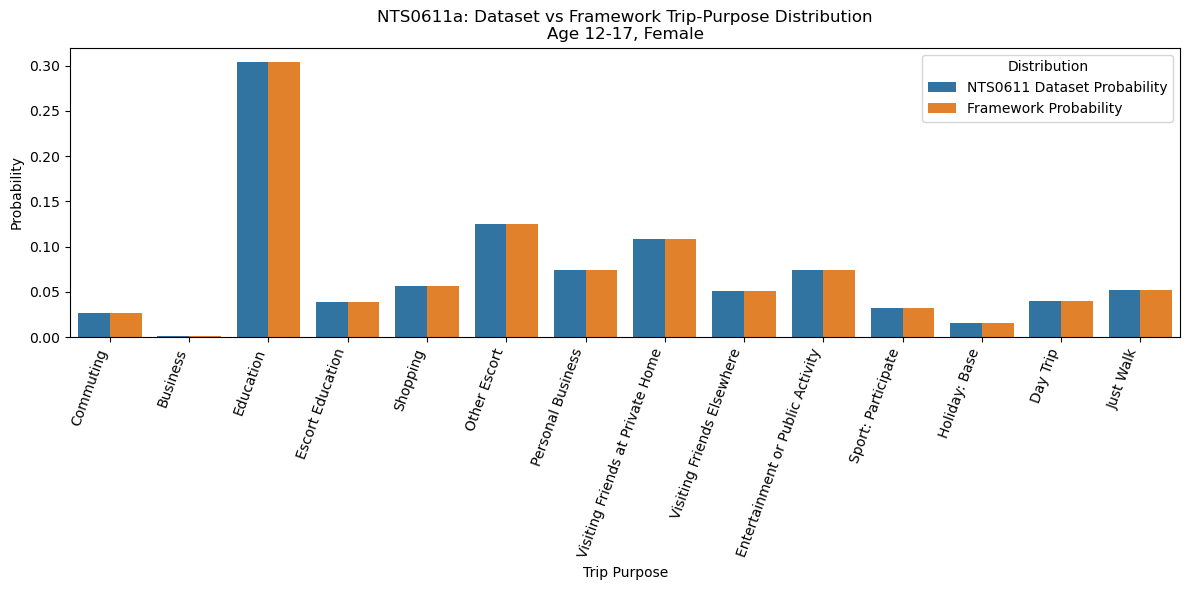

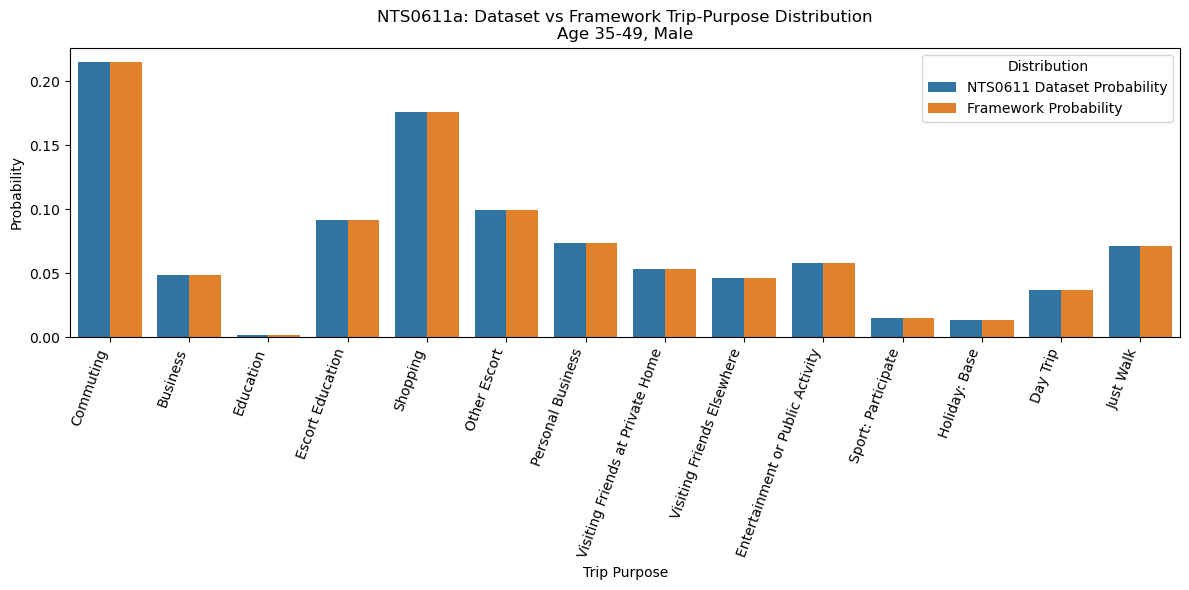

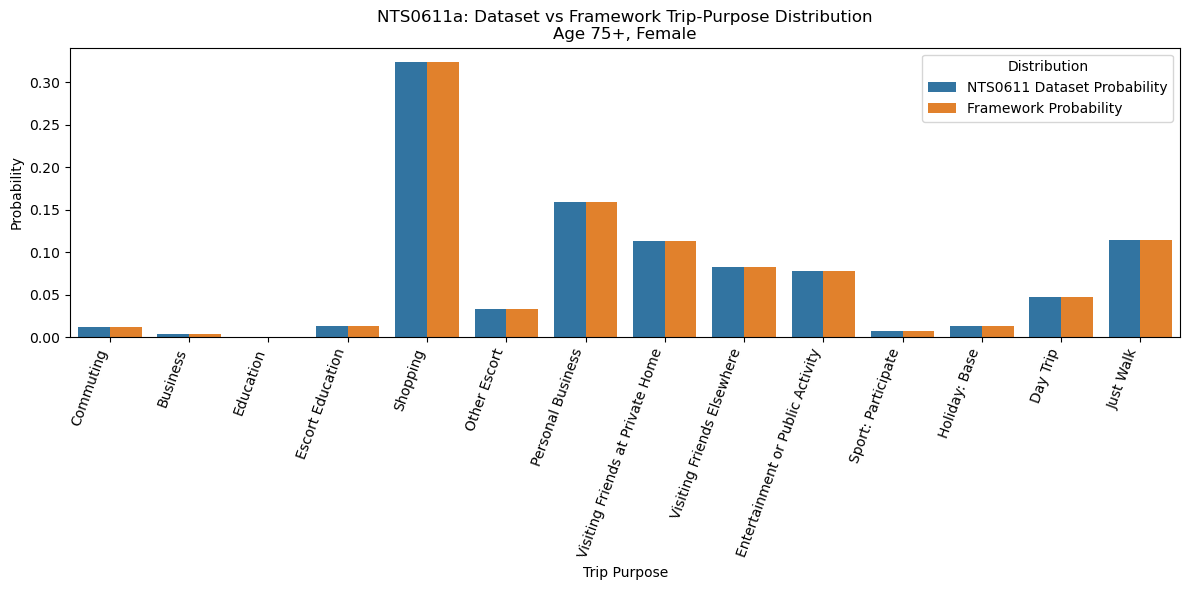

In [6]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Save a comparison plot for every validated case while showing
# only three representative cases in the notebook.

def build_comparison_plot(age, Sex, comparison_df):
    plot_df = (
        comparison_df[
            [
                "NTS0611 Dataset Probability",
                "Framework Probability",
            ]
        ]
        .rename_axis("Trip Purpose")
        .reset_index()
        .melt(
            id_vars="Trip Purpose",
            var_name="Distribution",
            value_name="Probability",
        )
    )

    figure, axis = plt.subplots(figsize=(12, 6))
    sns.barplot(
        data=plot_df,
        x="Trip Purpose",
        y="Probability",
        hue="Distribution",
        ax=axis,
    )
    axis.tick_params(axis="x", rotation=70)
    for label in axis.get_xticklabels():
        label.set_horizontalalignment("right")
    axis.set_title(
        "NTS0611a: Dataset vs Framework Trip-Purpose Distribution\n"
        f"Age {age}, {Sex}"
    )
    axis.set_xlabel("Trip Purpose")
    axis.set_ylabel("Probability")
    figure.tight_layout()
    return figure


plot_output_directory.mkdir(parents=True, exist_ok=True)
saved_plot_paths = {}

for (age, Sex), comparison_df in comparison_tables.items():
    figure = build_comparison_plot(age, Sex, comparison_df)
    age_label = age.replace("+", "plus")
    Sex_label = Sex.lower()
    plot_path = plot_output_directory / (
        f"nts0611_{age_label}_{Sex_label}.png"
    )
    figure.savefig(plot_path, dpi=300, bbox_inches="tight")
    plt.close(figure)
    saved_plot_paths[(age, Sex)] = plot_path

print(f"Saved {len(saved_plot_paths)} plots to {plot_output_directory}")

preferred_display_cases = [
    ("12-17", "Female"),
    ("35-49", "Male"),
    ("75+", "Female"),
]
display_case_keys = [
    case_key
    for case_key in preferred_display_cases
    if case_key in comparison_tables
]

# Fill any missing preferred position with another available case.
for case_key in comparison_tables:
    if len(display_case_keys) == 3:
        break
    if case_key not in display_case_keys:
        display_case_keys.append(case_key)

for age, Sex in display_case_keys:
    figure = build_comparison_plot(
        age,
        Sex,
        comparison_tables[(age, Sex)],
    )
    plt.show()

### Interpretation

A complete PASS demonstrates that the framework correctly translated every unique unconstrained demographic lookup case into its `Age × Sex` conditions, retrieved the corresponding 14 NTS0611 trip-purpose categories, and preserved their probabilities when no implemented constraint was active. This evaluates lookup and distribution preservation across the full unconstrained lookup space; it does not independently validate the behavioural realism of the NTS0611 dataset estimates.